# Detph and Velocity GT analysis

Overlay GT depth and velocity

Note: use env seg_clone_2311

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mmengine.dataset import Compose

from mmseg.datasets.sys100_ppp_heatmap_dataset import Sys100PPPHeatmapDataset
from mmseg.datasets.transforms.sys100_ppp_transforms import LoadSys100Sample, BuildPPPHeatmap

/home/lorenz-linux/miniconda3/envs/seg_clone_2311/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SYS100_ROOT = '/home/lorenz-linux/repositories/aumovio_data/aumovio_sys100_data'

In [4]:
pipeline = Compose([
    LoadSys100Sample(
        sys100_root=SYS100_ROOT,
        out_img_size=(544, 1792),
        undistort=True,
        fovs=(110, 48.4),
    ),
    BuildPPPHeatmap(
        thres=0.05,
        clip_depth=(0.0, 150.0),
        clip_vel=(-10.0, 10.0),
    ),
])

0 valid, 0 error files: 100%|██████████| 1/1 [00:00<00:00, 205.65it/s]


In [5]:
dataset = Sys100PPPHeatmapDataset(
    sys100_root=SYS100_ROOT,
)


0 valid, 0 error files: 100%|██████████| 1/1 [00:00<00:00, 218.24it/s]


In [ ]:
sample0 = pipeline(dataset[0])
H, W = sample0["gt_seg_map"].shape[:2]

count_map = np.zeros((H, W), dtype=np.float32)
depth_sum = np.zeros((H, W), dtype=np.float32)
vel_sum   = np.zeros((H, W), dtype=np.float32)

start = 100
num_frames = 1

for i in range(start, start + num_frames):
    res = pipeline(dataset[i])
    gt = res["gt_seg_map"]  # (H,W,3)

    mask = gt[..., 0] > 0
    depth = gt[..., 1]
    vel   = gt[..., 2]

    count_map[mask] += 1
    depth_sum[mask] += depth[mask]
    vel_sum[mask]   += vel[mask]


In [ ]:
# compute the per-pixel mean of depth and velocity over time (while avoiding division-by-zero)
eps = 1e-6
mean_depth = depth_sum / (count_map + eps)
mean_vel   = vel_sum   / (count_map + eps)


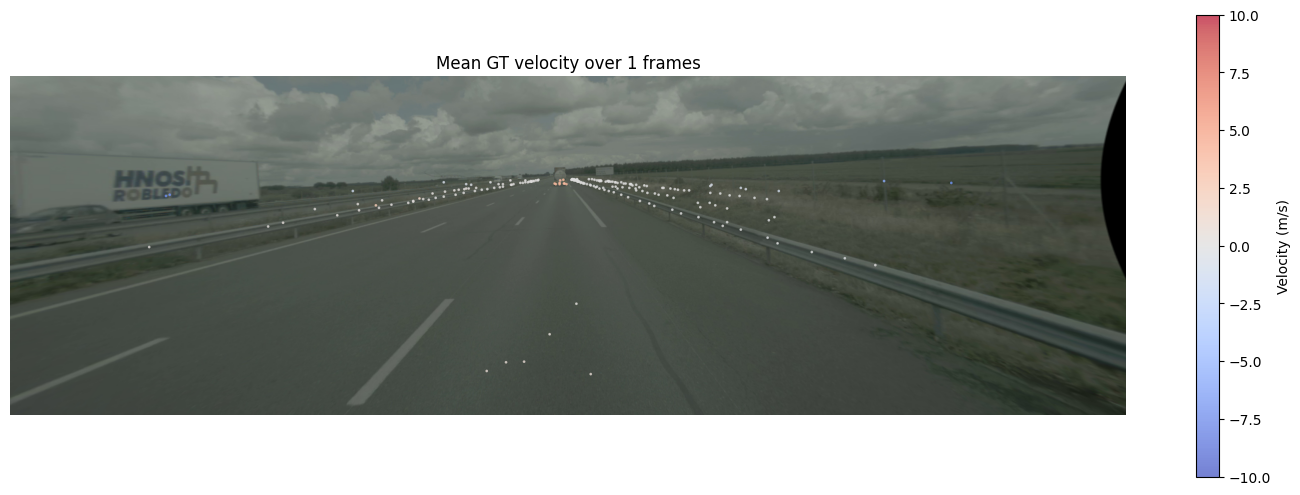

In [21]:
img = res["img"]  # uint8 HWC

plt.figure(figsize=(18, 6))
plt.imshow(img)

# --- extract points ---
mask = np.isfinite(mean_vel) & (mean_vel != 0)
ys, xs = np.where(mask)
vals = mean_vel[ys, xs]

# --- scatter as big dots ---
plt.scatter(
    xs,
    ys,
    c=vals,
    cmap="coolwarm",
    vmin=-10,
    vmax=10,
    s=1,
    alpha=0.7,
)

plt.colorbar(label="Velocity (m/s)")
plt.title(f"Mean GT velocity over {num_frames} frames")
plt.axis("off")
plt.show()

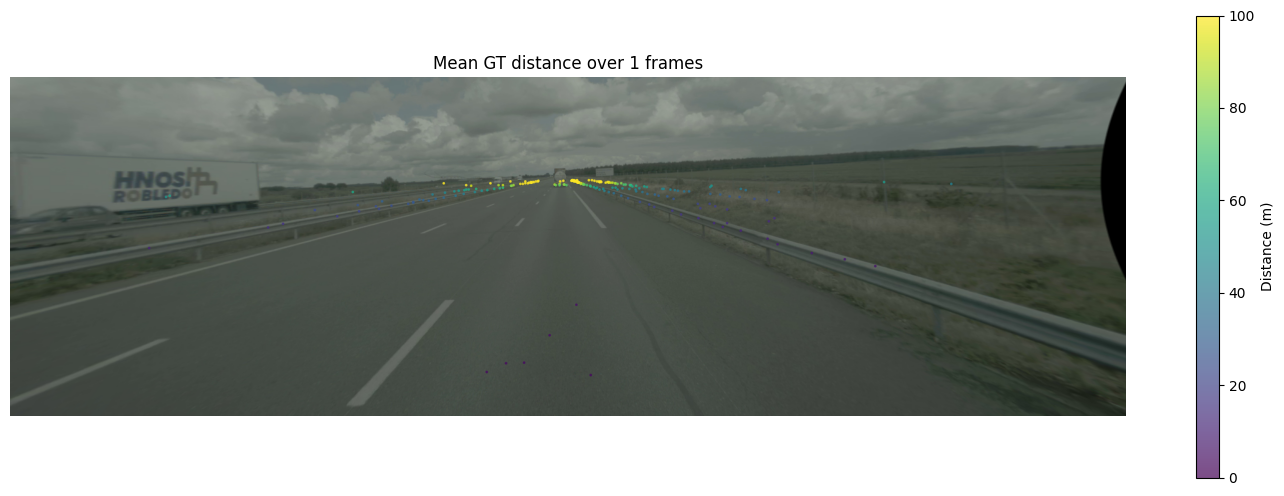

In [22]:
img = res["img"]  # uint8 HWC

plt.figure(figsize=(18, 6))
plt.imshow(img)

# --- extract points ---
mask = np.isfinite(mean_depth) & (mean_depth > 0)
ys, xs = np.where(mask)
vals = mean_depth[ys, xs]

# --- scatter distance ---
plt.scatter(
    xs,
    ys,
    c=vals,
    cmap="viridis",
    vmin=0,
    vmax=100,   # adjust to your radar range
    s=1,
    alpha=0.7,
)

plt.colorbar(label="Distance (m)")
plt.title(f"Mean GT distance over {num_frames} frames")
plt.axis("off")
plt.show()

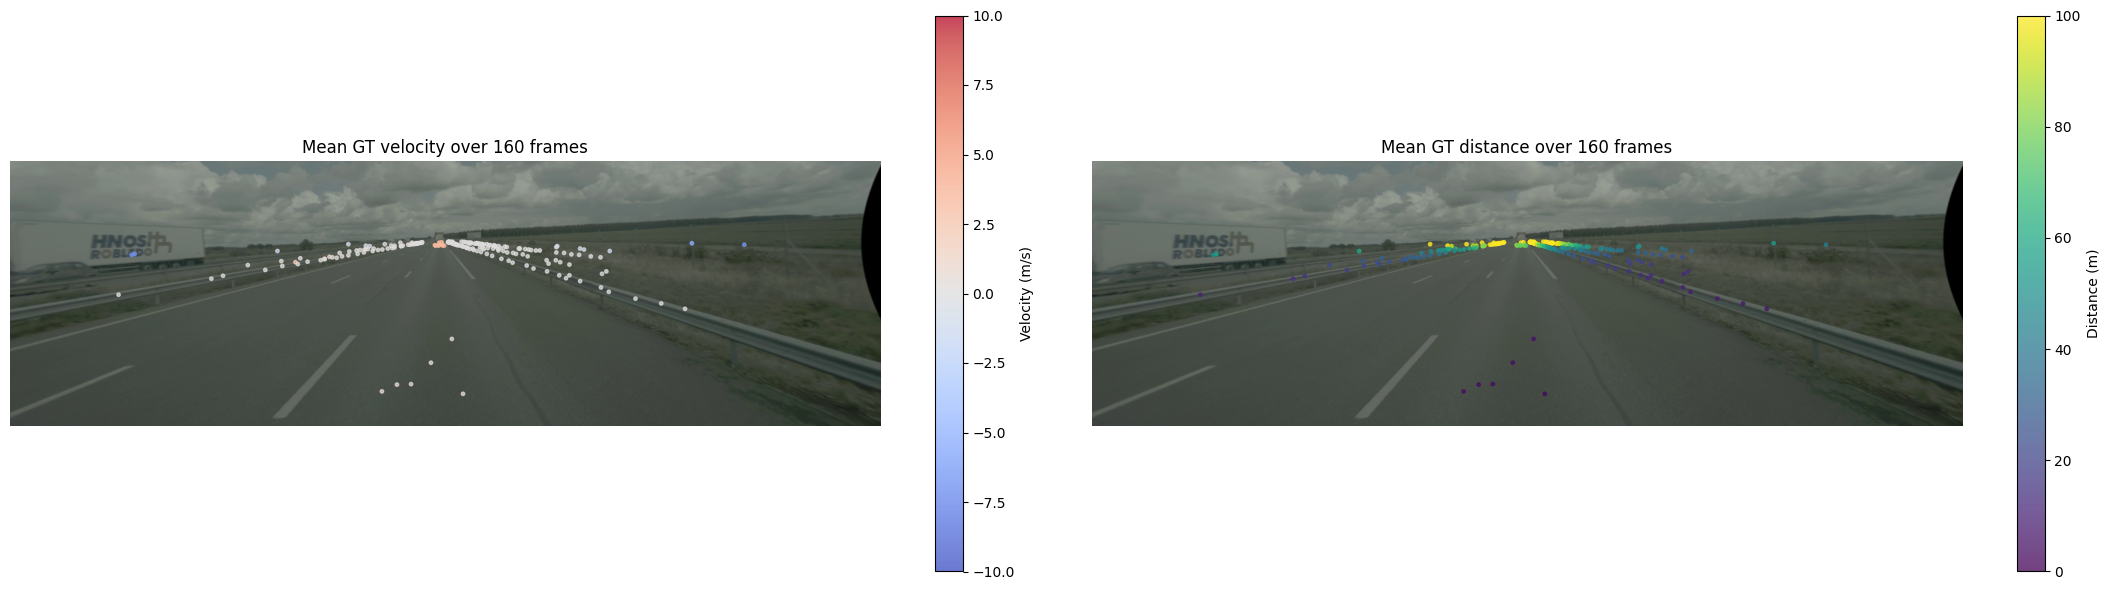

In [ ]:
img = res["img"]  # uint8 HWC

# --- extract points ---
mask = np.isfinite(mean_vel) & (mean_vel != 0)
ys, xs = np.where(mask)

vel_vals = mean_vel[ys, xs]
depth_vals = mean_depth[ys, xs]

fig, axs = plt.subplots(1, 2, figsize=(22, 6))

# =====================================================
# Velocity plot
# =====================================================
axs[0].imshow(img)

sc_vel = axs[0].scatter(
    xs,
    ys,
    c=vel_vals,
    cmap="coolwarm",
    vmin=-10,
    vmax=10,
    s=6,          # dot size
    alpha=0.75,
)

axs[0].set_title(f"Mean GT velocity over {num_frames} frames")
axs[0].axis("off")
plt.colorbar(sc_vel, ax=axs[0], label="Velocity (m/s)")

# =====================================================
# Distance plot
# =====================================================
axs[1].imshow(img)

sc_dist = axs[1].scatter(
    xs,
    ys,
    c=depth_vals,
    cmap="viridis",
    vmin=0,
    vmax=100,     # adjust to radar range
    s=6,
    alpha=0.75,
)

axs[1].set_title(f"Mean GT distance over {num_frames} frames")
axs[1].axis("off")
plt.colorbar(sc_dist, ax=axs[1], label="Distance (m)")

plt.tight_layout()
plt.show()
